## Step 1: Load and prepare the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_score, recall_score, accuracy_score,
                             roc_auc_score, roc_curve)

df = pd.read_csv("data.csv")   # use your actual file name
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [2]:
print(df.shape)
df.info()
print(df.isnull().sum().sum())
print(df['diagnosis'].value_counts())

(569, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se    

In [3]:
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})   # 1 = malignant, 0 = benign
df['diagnosis'].value_counts()

diagnosis
0    357
1    212
Name: count, dtype: int64

## Step 2: Train-test split and standardize

In [4]:
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on train only
X_test_s = scaler.transform(X_test)         # only transform on test
print(X_train_s.shape, X_test_s.shape)

(455, 30) (114, 30)


## Step 3: Fit the model

In [5]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)

y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]   # probability of malignant

## Step 4: Evaluate

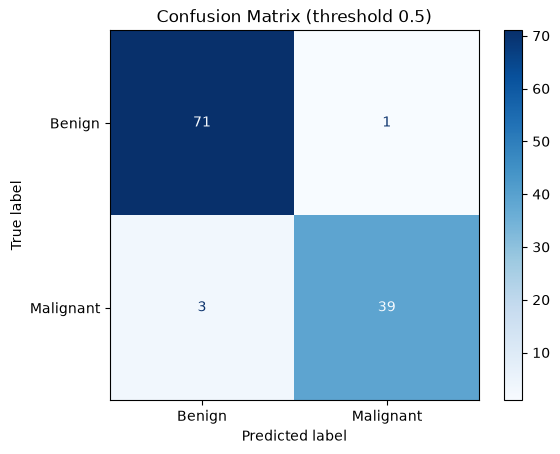

In [6]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Malignant']).plot(cmap='Blues')
plt.title('Confusion Matrix (threshold 0.5)')
plt.show()

In [7]:
print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))
print()
print(classification_report(y_test, y_pred, target_names=['Benign', 'Malignant']))

Accuracy : 0.965
Precision: 0.975
Recall   : 0.929
ROC-AUC  : 0.996

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



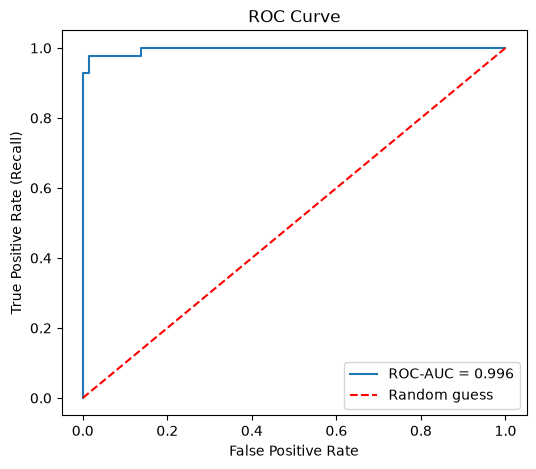

In [8]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc_score(y_test, y_prob):.3f}')
plt.plot([0, 1], [0, 1], 'r--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()
plt.show()

## Step 5: Tune the threshold and explain the sigmoid

In [9]:
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred_t = (y_prob >= t).astype(int)
    rows.append({'Threshold': t,
                 'Precision': round(precision_score(y_test, pred_t), 3),
                 'Recall': round(recall_score(y_test, pred_t), 3),
                 'Accuracy': round(accuracy_score(y_test, pred_t), 3)})
pd.DataFrame(rows)

,Threshold,Precision,Recall,Accuracy
0,0.2,0.911,0.976,0.956
1,0.3,0.976,0.976,0.982
2,0.4,0.976,0.952,0.974
3,0.5,0.975,0.929,0.965
4,0.6,1.000,0.905,0.965
5,0.7,1.000,0.905,0.965
6,0.8,1.000,0.857,0.947


## ## Threshold choice
I chose a threshold of 0.4 instead of 0.5. In cancer screening, missing a malignant case is worse than a false alarm. At 0.4, missed malignant cases dropped from 3 to 2 (recall about 0.95), while precision stayed about 0.98.

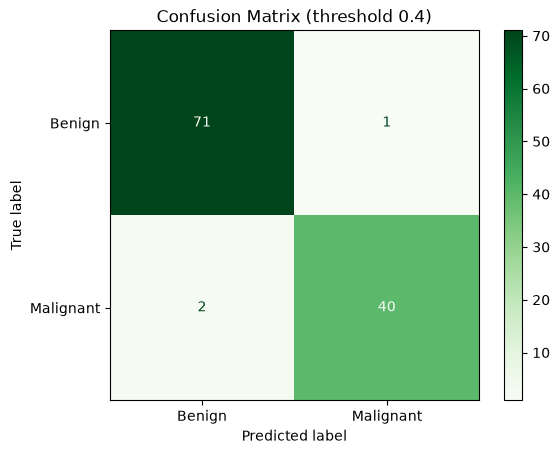

In [10]:
chosen = 0.4   # change after looking at the table
pred_c = (y_prob >= chosen).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_c),
                       display_labels=['Benign', 'Malignant']).plot(cmap='Greens')
plt.title(f'Confusion Matrix (threshold {chosen})')
plt.show()

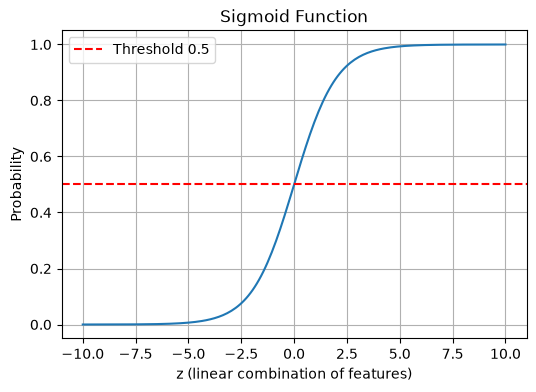

In [11]:
z = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-z))
plt.figure(figsize=(6, 4))
plt.plot(z, sigmoid)
plt.axhline(0.5, color='red', linestyle='--', label='Threshold 0.5')
plt.xlabel('z (linear combination of features)')
plt.ylabel('Probability')
plt.title('Sigmoid Function')
plt.legend()
plt.grid(True)
plt.show()

## Sigmoid function
Logistic regression first computes `z = w1*x1 + w2*x2 + ... + b`, then passes it through the sigmoid: `sigmoid(z) = 1 / (1 + e^(-z))`. This squeezes any number into the range 0 to 1, so the output can be read as a probability. If the probability is at least the threshold (0.5 by default), the model predicts class 1 (malignant), otherwise class 0 (benign). Changing the threshold trades precision against recall.

In [12]:
coef = pd.Series(model.coef_[0], index=X.columns).sort_values(ascending=False)
print(coef.head(5))
print(coef.tail(5))

texture_worst          1.434093
radius_se              1.233325
symmetry_worst         1.061264
concave points_mean    0.952813
concavity_worst        0.911406
dtype: float64
symmetry_se            -0.330658
texture_se             -0.407611
compactness_mean       -0.439546
fractal_dimension_se   -0.593876
compactness_se         -0.906925
dtype: float64
